# 5.1 Least Squares Global Localization

Least Squares Positioning is a well-known algorithm for estimating the robot pose $\mathbf{x}$ given a set of known landmarks in a map (see Fig. 1).

<figure style="text-align:center">
  <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/localization/images/fig5-1-ls-positioning.png" width="500" alt="">
  <figcaption>Fig. 1. Least Squares positioning: the robot pose $\mathbf{x}$ is unknown, and it is estimated from the measurements (here, the distances $d_i$) to landmarks $\mathbf{m}_i$ at known positions.</figcaption>
</figure>

Given a vector of measurements $\mathbf{z}$ that is related to the unknown pose $\mathbf{x}$ by the **linear observation model**:

$$\mathbf{z}_{m \times 1} = H_{m \times n} \, \mathbf{x}_{n \times 1} + \mathbf{e}_{m \times 1}$$

Least Squares finds the "best" $\mathbf{x}$, called $\hat{\mathbf{x}}$, where:
- $n$ is the dimension of the state ($n=3$ for planar poses, position plus orientation),
- $m$ represents the number of observation constraints (equations),
- $H$ is the matrix that codifies the observation model relating the measurements $\mathbf{z}$ with the robot pose $\mathbf{x}$, and
- $\mathbf{e}$ is the error affecting the measurements.

**What does $H$ represent?** $H\mathbf{x}$ gives the measurements that we would ideally get (without error) if the robot were at pose $\mathbf{x}$. It has one **row per measurement** and one **column per component of the pose**, and each element $H_{ij} = \partial z_i / \partial x_j$ tells how much the measurement $z_i$ changes when the pose component $x_j$ changes. For example, a GPS-like sensor providing the robot position $[x, y]^T$, but not its orientation, would be modeled as:

$$
\begin{bmatrix} z_1 \\ z_2 \end{bmatrix} =
\underbrace{\begin{bmatrix} 1 & 0 & 0 \\ 0 & 1 & 0 \end{bmatrix}}_{H}
\begin{bmatrix} x \\ y \\ \theta \end{bmatrix} +
\begin{bmatrix} e_1 \\ e_2 \end{bmatrix}
$$

Notice that the third column of $H$ is zero: no measurement depends on $\theta$, so these measurements alone can't tell us the robot orientation (it is *non-observable*, as we will see in the next section). Many sensors, like the range sensor in Fig. 1, are not linear, so their observation model can't be written as $H\mathbf{x}$. In that case (Section 5.1.3), the Jacobian $J_h$ of $\mathbf{h}$ will play the role of $H$ around the current estimate.

This simple concept, nevertheless, has to be modified in order to be used in real scenarios:

## 5.1.1 Pseudo-inverse

Generally, to solve an equation system, we only need as many equations as variables. In the robot localization problem, each observation sets an equation, while the variables are the components of the state/pose, $\mathbf{x}$.

In such a case, where $m=n$, if the $n$ equations are independent ($\text{rank}(H)=n$), a direct solution exists:

$$\hat{\mathbf{x}} = H^{-1} \mathbf{z}$$

So a unique solution exists if $H$ is invertible, that is, $H$ is a square matrix with $\det(H) \neq 0$. On the contrary, if there are fewer independent equations than variables ($\text{rank}(H) < n$), the pose is **non-observable**: there are infinitely many solutions for $\mathbf{x}$ (e.g. the GPS-like sensor above, with $\text{rank}(H) = 2 < 3$, can't determine $\theta$).

However, in real scenarios typically there are available more observations than variables ($m>n$). An approach to address this could be to drop some of the additional equations, but given that observations $\mathbf{z}$ are inaccurate (they have been affected by some error, i.e., $\mathbf{z}=H\mathbf{x}+\mathbf{e}$), we may use the additional information to try to mitigate such error. However, by doing that $H$ is not a square matrix anymore, hence not being invertible, and no exact solution exists.

Two tools can help us at this point. The first one is the utilization of **Least Squares** to find the closest possible $\hat{\mathbf{x}}$, i.e. the one where the squared error ($\mathbf{e} = \mathbf{z} - H\mathbf{x}$) is minimal:

$$\hat{\mathbf{x}} = \arg\min_{\mathbf{x}} \mathbf{e}^T\mathbf{e} = \arg\min_{\mathbf{x}} [(\mathbf{z}-H\mathbf{x})^T(\mathbf{z}-H\mathbf{x})] = \arg\min_{\mathbf{x}} \| \mathbf{z}-H\mathbf{x} \|^2$$

which has a closed-form solution using the **pseudo-inverse** of a matrix:

$$\hat{\mathbf{x}} = \underbrace{(H^T H)^{-1} H^T}_{\textit{pseudo-inverse }(H^+)} \mathbf{z}$$

The **pseudo-inverse**, in contrast to the normal inverse operation, can be used in non-square matrices! It only requires at least $n$ independent constraints, so that $\text{rank}(H)=n$ and the $n \times n$ matrix $H^T H$ is invertible.

Curious about how is that expression reached?

To find the estimate $\hat{\mathbf{x}}$ that minimizes $\| \mathbf{z}-H\mathbf{x} \|^2$, we take its derivative with respect to $\mathbf{x}$ and set it to zero:

$$
\frac{\partial \| \mathbf{z}-H\mathbf{x} \|^2}{\partial \mathbf{x}} = -2H^T(\mathbf{z}-H\mathbf{x}) = \mathbf{0}
$$

Rearranging this equation we get:

$$
H^TH\mathbf{x} = H^T \mathbf{z}
$$

And finally, assuming $H^TH$ invertible, we can solve for $\hat{\mathbf{x}}$ as:

$$\hat{\mathbf{x}} = (H^T H)^{-1} H^T \mathbf{z}$$

This is the **Least Squares solution** for the state vector $\hat{\mathbf{x}}$.

In [13]:
%matplotlib inline

# IMPORTS

import math

import numpy as np
from numpy import linalg
import matplotlib.pyplot as plt
import scipy
from scipy import stats
from IPython.display import display, clear_output
import time
import ipywidgets as widgets

import sys
sys.path.append("..")
from utils.PlotEllipse import PlotEllipse
from utils.DrawRobot import DrawRobot
from utils.tcomp import tcomp
from utils.tinv import tinv, jac_tinv1 as jac_tinv
from utils.Jacobians import J1, J2

### **<span style="color:green"><b><i>ASSIGNMENT 1: Playing with a robot in a corridor</i></b></span>**

The following code illustrates a simple scenario where a robot is in a corridor looking at a door, which is placed at the origin of the reference system (see Fig. 2). The robot is equipped with a laser scanner able to measure distances, and takes a number of observations $\mathbf{z}$. The robot is placed 3 meters away from the door, but this information is unknown for it. **Your goal is** to estimate the position of the robot in this 1D world using such measurements. $\\[5pt]$

<figure style="text-align:center">
  <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/localization/images/fig5-1-corridor.png" alt="">
  <figcaption>Fig. 2. Simple 1D scenario with a robot equipped with a laser scanner measuring distance to a door. Below the axis, the 5 readings $z_1, \dots, z_5$ of this assignment, measured from the door: because of the measurement error, they are spread around the true position of the robot.</figcaption>
</figure>

In this 1D world the pose is just the robot position, $\mathbf{x} = [x]$ ($n=1$), and each of the $m=5$ laser readings measures it directly, so every row of $H$ is a 1: $H = [1, 1, 1, 1, 1]^T$. The following code cell shows the dimensions of all the actors involved in LS-positioning. Complete it for computing the robot pose $\hat{\mathbf{x}}$ from the available information. *Recall [`np.linalg.inv()`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.inv.html).*

*Note that with this configuration the laser is directly measuring the robot position. If the laser was measuring distances to an object placed at a different location $m_i$, then the equation should be $z_i=[H\mathbf{x}]_i-m_i$, being $[H\mathbf{x}]_i$ the element $i$ of the vector $H\mathbf{x}$.*

In [3]:
# Set the robot pose to unknown
x = np.vstack(np.array([None]))

# Sensor measurements to the door
z = np.vstack(np.array([3.7,2.9,3.6,2.5,3.5]))

# Observation model
H = np.ones(np.array([5,1]))

print ("Dimensions:")
print ("Pose x:         " + str(x.shape))
print ("Observations z: " + str(z.shape))
print ("Obs. model H:   " + str(H.shape))
print ("H.T@H:          " + str((H.T@H).shape))
print ("inv(H.T@H):     " + str((np.linalg.inv(H.T@H)).shape))
print ("H.T@z :         " + str((H.T@z).shape))

# Do Least Squares Positioning
x = linalg.inv(H.T @ H) @ H.T @ z

print('\nLS-Positioning')
print('x = ' + str(x[0]))

Dimensions:
Pose x:         (1, 1)
Observations z: (5, 1)
Obs. model H:   (5, 1)
H.T@H:          (1, 1)
inv(H.T@H):     (1, 1)
H.T@z :         (1, 1)

LS-Positioning
x = [3.24]


<span style="color:blue">Expected output</span>

```
x = [3.24]
```

## 5.1.2 Weighted measurements

In cases where multiple sensors affected by different noise profiles are used, or in those where the robot is using a sensor with a varying error (*e.g.* typically radial laser scans are more accurate while measuring distances to close objects), measurements are not equally reliable, so it is interesting to weight the contribution of such measurements while retrieving the robot pose.

For example, we are going to consider a sensor whose accuracy drops the further the observed landmark is, so the measurements to far landmarks are less reliable than those to close ones, and they should have less weight in the estimation.

To achieve this, given a *covariance* matrix $Q$ describing the error in the measurements, each element $e_i = z_i - [H\mathbf{x}]_i$ of the error vector $\mathbf{e}$ is inversely weighted by the uncertainty (variance) of the measurement $z_i$, that is, it is divided by $\sigma_{z_i}^2$: the further the landmark, the larger $\sigma_{z_i}^2$ and the smaller the weight $1/\sigma_{z_i}^2$ of its measurement. The equations above are then rewritten as:

$$\hat{\mathbf{x}} = \arg\min_{\mathbf{x}} \mathbf{e}^T Q^{-1} \mathbf{e} = \arg\min_{\mathbf{x}} [(\mathbf{z}-H\mathbf{x})^T Q^{-1} (\mathbf{z}-H\mathbf{x})]$$

$$
\begin{aligned}
  &\hat{\mathbf{x}} = (H^T Q^{-1} H)^{-1} H^T Q^{-1} \mathbf{z} &\text{(1. Best estimation)}\\
  &\Sigma_{\hat{\mathbf{x}}} = (H^T Q^{-1} H)^{-1} &\text{(2. Covariance of the estimation, propagated from } Q \text{)}\\
\end{aligned}
$$

If the measurement errors $e_i$ are mutually independent, $Q$ is diagonal. Example with three measurements having different uncertainty ($\sigma_{z_1}^2$, $\sigma_{z_2}^2$, $\sigma_{z_3}^2$):

$$
\mathbf{e}^T Q^{-1} \mathbf{e} = [e_1 \; e_2 \; e_3]
\begin{bmatrix} 1 / \sigma_{z_1}^2 & 0 & 0 \\ 0 & 1/\sigma_{z_2}^2 & 0 \\ 0 & 0 & 1/\sigma_{z_3}^2 \end{bmatrix}
\begin{bmatrix} e_1 \\ e_2 \\ e_3 \end{bmatrix}
= \frac{e_1^2}{\sigma_{z_1}^2} + \frac{e_2^2}{\sigma_{z_2}^2} + \frac{e_3^2}{\sigma_{z_3}^2}
= \sum_{i=1}^m \frac{e_i^2}{\sigma_{z_i}^2}
$$

In this way, the bigger the $\sigma_{z_i}^2$, the smaller its contribution to the pose's computation.

Moreover, if the error in the measurements is zero-mean Gaussian, i.e. $\mathbf{e} \sim \mathcal{N}(\mathbf{0}, Q)$, then $\mathbf{z} \sim \mathcal{N}(H\mathbf{x}, Q)$, and the Weighted Least Squares solution is the same as the **Maximum Likelihood** (ML) estimation, that is, the pose that maximizes the likelihood function $\mathcal{L}(\mathbf{x}) = p(\mathbf{z}|\mathbf{x})$:

$$\hat{\mathbf{x}}_{ML} = \arg\max_{\mathbf{x}} p(\mathbf{z}|\mathbf{x}) = \arg\min_{\mathbf{x}} [(\mathbf{z}-H\mathbf{x})^T Q^{-1} (\mathbf{z}-H\mathbf{x})] = \hat{\mathbf{x}}_{LS}$$

### **<span style="color:green"><b><i>ASSIGNMENT 2: Adding growing uncertainty</i></b></span>**

We have new information! The manufacturer of the laser scanner mounted on the robot wrote an email telling us that the device is considerably more inaccurate for further distances. Concretely, the uncertainty of each measurement is characterized by $\sigma_{z_i}^2=e^{z_i}$ (the laser is not so accurate, being polite).

With this new information, implement the computation of the weighted LS-positioning so you can compare the previously estimated position with the new one.

In [4]:
# Sensor measurements to the door
z = np.vstack(np.array([3.7,2.9,3.6,2.5,3.5]))

# Uncertainty of the measurements
Q = np.eye(5)*np.exp(z)

# Observation model
H = np.ones(np.array([5,1]))

# Do Least Squares Positioning
x = linalg.inv(H.T @ H) @ H.T @ z

# Do Weighted Least Squares Positioning
x_w = linalg.inv(H.T @ linalg.inv(Q) @ H) @ H.T @ linalg.inv(Q) @ z

print('\nLS-Positioning')
print('x = ' + str(x[0]))

print('\nWeighted-LS-Positioning')
print('x = ' + str(np.round(x_w[0],2)))


LS-Positioning
x = [3.24]

Weighted-LS-Positioning
x = [3.01]


<span style="color:blue">Expected output</span>

```
LS-Positioning
x = [3.24]

Weighted-LS-Positioning
x = [3.01]
```

## 5.1.3 Non-linear Least Squares

Until now we have assumed that $\hat{\mathbf{x}}$ can be solved as a simple system of equations, i.e. $H$ is a matrix. Nevertheless, typically observation (sensor) models are non-linear, that is: $\mathbf{z} = \mathbf{h}(\mathbf{x})$ (instead of $\mathbf{z} = H\mathbf{x}$), being $\mathbf{h}(\mathbf{x})$ a function, so the problem now becomes:

$$\hat{\mathbf{x}} = \arg\min_{\mathbf{x}} \|\mathbf{z}-\mathbf{h}(\mathbf{x})\|^2$$

where $\mathbf{z}$ is a vector of $m$ numbers (the observations), not random variables.

Unlike linear LS, this generally has no direct closed-form solution, so we start from an estimate $\mathbf{x}_k$ and locally linearize it with a Taylor expansion:

$$\mathbf{h}(\mathbf{x}) = \mathbf{h}(\mathbf{x}_k+\boldsymbol{\delta}) \cong \mathbf{h}(\mathbf{x}_k) + J_{h_k}\boldsymbol{\delta}$$

where $J_{h_k}$ is the $m \times n$ Jacobian of $\mathbf{h}$ evaluated at $\mathbf{x}_k$:

$$
J_{h_k} = \left.\frac{\partial \mathbf{h}}{\partial \mathbf{x}}\right|_{\mathbf{x}_k} =
\begin{bmatrix}
    \frac{\partial h_1}{\partial x_1} & \cdots & \frac{\partial h_1}{\partial x_n} \\
    \vdots & & \vdots \\
    \frac{\partial h_m}{\partial x_1} & \cdots & \frac{\partial h_m}{\partial x_n}
\end{bmatrix}_{\mathbf{x}_k}
$$

This converts each iteration into a **linear LS problem in $\boldsymbol{\delta}$**:

$$\boldsymbol{\delta}^* = \arg\min_{\boldsymbol{\delta}} \|\underbrace{\mathbf{z}-\mathbf{h}(\mathbf{x}_k)}_{\textit{error vector } \mathbf{e}}-J_{h_k}\boldsymbol{\delta}\|^2 \quad \longrightarrow \quad \mathbf{x}_{k+1} = \mathbf{x}_k + \boldsymbol{\delta}^*$$

which is repeated until $\boldsymbol{\delta}^*$ is sufficiently small. As in the linear case, the $\boldsymbol{\delta}$ that makes the previous squared norm minimum is (writing $J_h$ for the Jacobian at the current estimate):

$$\underbrace{\boldsymbol{\delta}}_{n \times 1} = \underbrace{(J_h^T J_h)^{-1}}_{n \times n}\underbrace{J_h^T}_{n \times m} \underbrace{\mathbf{e}}_{m \times 1}$$

The weighted form of the $\boldsymbol{\delta}$ computation results:

$$\boldsymbol{\delta} = (J_h^T Q^{-1} J_h)^{-1}J_h^T Q^{-1} \mathbf{e}$$

Where:

- $Q$ is the measurement covariance (the *weighting matrix*),
- $J_h$ is the Jacobian of the observation model evaluated at the current estimate $\hat{\mathbf{x}}$, and
- $\mathbf{e} = \mathbf{z} - \mathbf{h}(\hat{\mathbf{x}})$ is the error of the observations $\mathbf{z}$ against the predicted ones $\mathbf{h}(\hat{\mathbf{x}})$ (computed using the map information).

As commented, there is no closed-form solution for the problem, but we can iteratively approximate it using the **Gauss-Newton algorithm**:

$$
\begin{aligned}
    &\hat{\mathbf{x}} = (\dots)  &\text{(0. Begin with an initial guess)} \\
    &\boldsymbol{\delta} = (J_h^T Q^{-1} J_h)^{-1} J_h^T Q^{-1} [\mathbf{z}-\mathbf{h}(\hat{\mathbf{x}})]  &\text{(1. Compute the incremental pose } \boldsymbol{\delta} = [\boldsymbol{\delta}_{xy}^T, \delta_\theta]^T \text{)} \\
    &\hat{\mathbf{x}} = \hat{\mathbf{x}} + \boldsymbol{\delta} &\text{(2. Update the estimation)} \\
    &\textit{if } \|\boldsymbol{\delta}_{xy}\| < T_1 \textit{ and } |\delta_\theta| < T_\theta \rightarrow \textit{stop} &\text{(3. Exit condition)}\\
    &\textit{else } \rightarrow \textit{goto (1.) with } \hat{\mathbf{x}} \\
\end{aligned}
$$

### LS positioning in practice

Suppose that a mobile robot equipped with a range sensor aims to localize itself in a map consisting of a number of landmarks by means of Least Squares and Gauss-Newton optimization. This problem is known as **multilateration** (also called *range-only positioning*): estimating the position $\mathbf{r} = [x, y]^T$ of the robot (whose pose is $\mathbf{x} = [x, y, \theta]^T = [\mathbf{r}, \theta]^T$) given the distances $d_i$ to a number of beacons $\mathbf{m}_i = [x_i, y_i]^T$ placed at known positions (a sort of indoor GPS). With three beacons, it is called **trilateration**.

For that, **you are provided with** the class `Robot` that implements the behavior of a robot that thinks that is placed at `pose` (that's its initial guess, obtained by composing odometry commands), but that has a real position `true_pose`. In addition, the variable `cov` models the uncertainty of its movement, and `var_d` represents the variance (noise) of the range measurements. Take a look at it below.


In [5]:
class Robot(object):
    """ Simulate a robot base and positioning.
    
        Attrs:
            pose: Position given by odometry (in this case true_pose affected by noise)
            true_pose: True position, selected by the mouse in this demo
            cov: Covariance for the odometry sensor. Used to add noise to pose
            var_d: Variance (noise) of each range measurement (sigma_d^2)
    """
    def __init__(self,
                 pose: np.ndarray,
                 cov: np.ndarray,
                 desv_d: int = 0):
        # Pose related        
        self.true_pose = pose
        self.pose = pose + np.sqrt(cov)@np.random.randn(3, 1)
        self.cov = cov
        
        # Sensor related
        self.var_d = desv_d**2
    
    def plot(self, fig, ax, **kwargs):
        DrawRobot(fig, ax, self.pose, color='red', label="Pose estimation (Odometry)", **kwargs)
        DrawRobot(fig, ax, self.true_pose, color="blue", label="Real pose", **kwargs)

### **<span style="color:green"><b><i>ASSIGNMENT 3a: Computing distances from the robot to the landmarks</i></b></span>**

**Implement the following function** to simulate how our robot observes the world. In this case, the landmarks in the map act as beacons: the robot can sense how far away they are without any information about angles. The robot uses a range sensor with the following observation model:

$$
z_i = d_i = h(\mathbf{x},\mathbf{m}_i) + e_i = \sqrt{(x_i-x)^2+(y_i-y)^2} + e_i = \|\mathbf{m}_i - \mathbf{r}\| + e_i
$$

where $\mathbf{m}_i = [x_i, y_i]^T$ stands for the $i^{th}$ landmark, $\mathbf{r} = [x, y]^T$ is the robot position, and $e_i$ is the error added by the sensor. Notice that the observation does not depend on the robot heading $\theta$, so $\theta$ is not observable from range-only measurements (see Fig. 3).

<figure style="text-align:center">
  <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/localization/images/fig5-1-range-only-model.png" width="500" alt="">
  <figcaption>Fig. 3. Range-only observation model: the measurement $z_i$ is the distance from the robot position $\mathbf{r}$ to the landmark $\mathbf{m}_i$, plus the sensor error $e_i$.</figcaption>
</figure>


Consider two scenarios in the function implementation:
- The measurement is carried out with an ideal sensor, so no noise nor uncertainty exists (`cov_d = 0`).
- The measurement comes from a real sensor affected by a given noise (`cov_d != 0`). We are going to consider that the range sensor is more accurate measuring distances to close landmarks than to far away ones. To implement this, consider that the noise grows with the root of the distance to the landmark, so the standard deviation of each measurement can be retrieved by:

$$
\sigma_{z_i} = \sigma_d\sqrt{z_i}
$$

that is, `np.sqrt(cov_d)*np.sqrt(z)`, being $\sigma_d^2$ (`cov_d`) the variance of the sensor. Recall that the sensor noise is modeled as a Gaussian distribution, so you have to define such distribution and take samples from it using the [`stats.norm()`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html) and [`rvs()`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.rv_continuous.rvs.html) functions.

In [6]:
def distance(pose: np.ndarray, m: np.ndarray, cov_d: int = 0) -> np.ndarray:
    """ Get observations for every landmark in the map.

    In this case our observations are range only.
    If cov_d > 0 then add Gaussian noise whose std grows with the root of the distance

    Args:
        pose: pose (true or noisy) of the robot taking observation
        m: Map containing all landmarks m_i, shape (2, nLandmarks)
        cov_d: Variance of the sensor (sigma_d^2)

    Returns
        z: numpy array containing distances to all obs. It has shape (nLandmarks,).
    """
    z = np.sqrt((m[0, :] - pose[0])**2 + (m[1, :] - pose[1])**2) # compute distances to all landmarks

    if cov_d > 0:
        z = z + stats.norm.rvs(0, np.sqrt(cov_d * z)) # add noise if needed

    return z

**Try your brand new function** with the following code:

In [7]:
pose = np.vstack([2, 2, 0.35])
m = np.array([[-5,-15],[20,56],[54,-18]]).T
cov_d = 0

# Compute distances from the sensor to the landmarks
z = distance(pose,m,cov_d)

# Now consider a noisy sensor
cov_d = 0.5
np.random.seed(seed=0)
z_with_noise = distance(pose,m,cov_d)

# Show the results
print('Measurements without noise:' + str(z))
print('Measurements with noise:   ' + str(z_with_noise))

Measurements without noise:[18.38477631 56.92099788 55.71355311]
Measurements with noise:   [23.73319805 59.05577186 60.87928514]


<span style="color:blue">Expected output</span>

```
Measurements without noise:[18.38477631 56.92099788 55.71355311]
Measurements with noise:   [23.73319805 59.05577186 60.87928514]
```

### **<span style="color:green"><b><i>ASSIGNMENT 3b: Implementing the algorithm</i></b></span>**

Finally, we get to implement the Least Squares algorithm for localization. We ask you to complete the gaps in the following function, which starts by initializing the Jacobian of the observation function (`jH`, that is, $J_h$) and takes as initial guess (`xEst`, that is, $\hat{\mathbf{x}}$) the pose at which the robot thinks it is as given by its odometry (`R1.pose`). Then, it enters into a loop until convergence is reached, where:

1. The distances `zEst` to each landmark from the estimated position `xEst` are computed, that is, the predicted observations $\mathbf{h}(\hat{\mathbf{x}})$. Recall that the map (landmark positions) is known (`w_map`).
2. The error $\mathbf{e} = \mathbf{z} - \mathbf{h}(\hat{\mathbf{x}})$ (`e`) is computed as the difference between the observations provided by the sensor `z` and the distances `zEst` computed at the previous point. Then, the residual error is computed as its norm, $\|\mathbf{e}\| = \sqrt{\mathbf{e}^T\mathbf{e}}$.
3. The Jacobian of the observation model is evaluated at the estimated robot position (`xEst`). This Jacobian has two columns (recall that $\theta$ is not observable) and as many rows as observations to the landmarks:

   $$
   J_h =
   \begin{bmatrix}
       -\frac{1}{\|\mathbf{m}_1 - \mathbf{r}\|}(x_1-x) & -\frac{1}{\|\mathbf{m}_1 - \mathbf{r}\|}(y_1-y) \\
       -\frac{1}{\|\mathbf{m}_2 - \mathbf{r}\|}(x_2-x) & -\frac{1}{\|\mathbf{m}_2 - \mathbf{r}\|}(y_2-y) \\
       \vdots & \vdots \\
       -\frac{1}{\|\mathbf{m}_N - \mathbf{r}\|}(x_N-x) & -\frac{1}{\|\mathbf{m}_N - \mathbf{r}\|}(y_N-y) \\
   \end{bmatrix}
   $$

   being $\mathbf{r} = [x, y]^T$ the estimated position in `xEst`, $\mathbf{m}_i = [x_i, y_i]^T$ the position of the $i^{th}$ landmark in the map, $N$ the number of landmarks, and $\|\mathbf{m}_i - \mathbf{r}\|$ the distance previously computed from the robot estimated position to the $i^{th}$ landmark.
4. The increment $\boldsymbol{\delta}$ (`incr`) is computed and added to the estimated pose (`xEst`). *Note: recall that $\boldsymbol{\delta} = (J_h^T Q^{-1} J_h)^{-1}J_h^T Q^{-1} \mathbf{e}$*

In [15]:
def LeastSquaresLocalization(R1: Robot,
                             w_map: np.ndarray,
                             z: np.ndarray,
                             nIterations=10,
                             tolerance=0.001,
                             delay=0.5) -> np.ndarray:
    """ Pose estimation using Gauss-Newton for least squares optimization
    
        Args:
            R1: Robot which pose we must estimate
            w_map: Map of the environment
            z: Observation received from sensor
            
            nIterations: sets the maximum number of iterations (default 10)
            tolerance: the loop stops when the norm of the increment delta is below it (convergence) (default 0.001)
            
            delay: Wait time used to visualize the different iterations (default 0.5)
            
        Returns:
            xEst: Estimated pose (x_hat)
    
    """
    
    iteration = 0
    
    # Initialization of useful variables
    incr = np.ones((2, 1)) # Increment delta
    jH = np.zeros((w_map.shape[1], 2)) # Jacobian J_h of the observation function of all the landmarks
    xEst = R1.pose #Initial estimation is the odometry position (usually noisy)
    log = '' # Report of the iterations (the output is cleared to animate the figure)
    
    # Let's go!
    while linalg.norm(incr) > tolerance and iteration < nIterations:
        #if plotting:
        plt.plot(xEst[0], xEst[1], '+r', markersize=1+math.floor((iteration*15)/nIterations))
        # Compute the predicted observation (from xEst) and their respective Jacobians

        # 1) TODO: Compute distance to each landmark from xEst (predicted observations h(x_hat), w/o noise)
        # 
        zEst = distance(xEst, w_map)

        # 2) TODO: error e = z - h(x_hat), difference between real observations and predicted ones.
        e = z - zEst
        residual = np.sqrt(e.T@e) # residual error = ||e|| = sqrt(e^T e)

        # 3) TODO: Compute the Jacobian J_h with respect to (x,y)
        # The jH is evaluated at our current guess (xEst)
        
        jH[:, 0] = (w_map[0, :] - xEst[:2, 0]) / zEst.flatten()
        jH[:, 1] = (w_map[1, :] - xEst[:2, 0]) / zEst.flatten()

        # The observation variances Q grow with the root of the distance
        Q = np.diag(R1.var_d*np.sqrt(z))

        # 4) TODO: Solve the equation --> compute the increment delta (incr)
        incr = linalg.solve(jH.T @ linalg.inv(Q) @ jH, jH.T @ linalg.inv(Q) @ e)
                    
        plt.plot([xEst[0, 0], xEst[0, 0]+incr[0]], [xEst[1, 0], xEst[1, 0]+incr[1]], 'r')
        xEst[0:2, 0] += incr
        
        log += "Iteration :" + str(iteration) + "\n"
        log += "  delta :   " + str(incr) + "\n"
        log += "  residual: " + str(residual) + "\n"
        
        iteration += 1
        
        # Show the current iteration
        clear_output(wait=True)
        display(plt.gcf())
        print(log)
        time.sleep(delay)

    plt.plot(xEst[0, 0], xEst[1, 0], '*g', markersize=14, label="Final estimation") #The last estimation is plot in green
    plt.legend()
    clear_output(wait=True)
    display(plt.gcf())
    print(log)
    
    return xEst

The next cell code launches our algorithm, so **we can try it!** This is done according to the following steps:

  1. The map `w_map` is built. In this case, the map consists of a number of landmarks (`nLandmarks`) randomly placed.
  2. You set the true position of the robot (`R1.true_pose`) with the sliders above the map.
  3. A new pose is generated from it, `R1.pose`, which represents the pose that the robot thinks it is in. This simulates a motion command from an arbitrary pose that ends up with the robot in `R1.true_pose`, but it thinks that it is in `R1.pose`.
  4. Then the robot takes a (noisy) range measurement to each landmark in the map.
  5. Finally, the robot employs a Least Squares definition of the problem and Gauss-Newton to iteratively optimize such a guess (`R1.pose`), obtaining a new (and hopefully better) estimation of its pose `xEst`.

  Each time you move a slider, the localization is run again from the new true position (with the same map).

  **Example**

  The figure below shows an example of execution of this code (once completed).

<figure style="text-align:center">
  <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/localization/images/fig5-1-1.png" width="500" alt="">
  <figcaption>Fig. 4. Example of LS positioning: the robot real pose (blue), the pose estimated by odometry (red) used as initial guess, the Gauss-Newton iterations (red lines) and the final estimation (green star).</figcaption>
</figure>

Output()

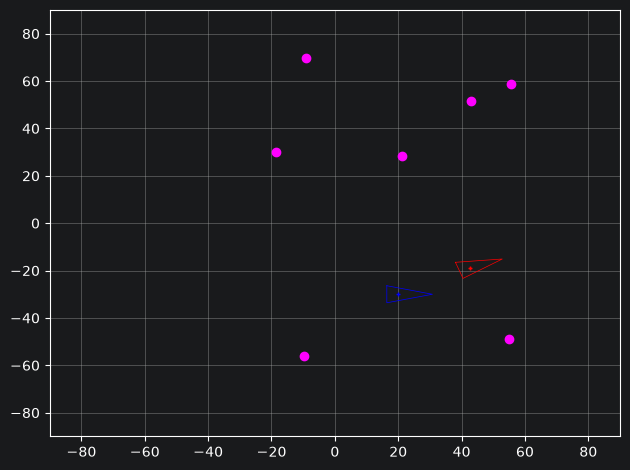

In [16]:
def main(nLandmarks=7, env_size=140):
    # MAP CREATION: randomly place the landmarks in a square environment with x,y in [-env_size/2, env_size/2]
    w_map = env_size*np.random.rand(2, nLandmarks) - env_size/2

    # ROBOT AND SENSOR CHARACTERIZATION
    desv_d = 0.5 # standard deviation (noise) of the range measurement
    cov = np.diag([25, 30, np.pi*180])**2 # covariance of the motion (odometry)

    # SLIDERS TO SET THE TRUE POSITION OF THE ROBOT
    x_w = widgets.FloatSlider(value=20.0, min=-env_size/2, max=env_size/2, step=1.0,
                              description='True x:', continuous_update=False)
    y_w = widgets.FloatSlider(value=-30.0, min=-env_size/2, max=env_size/2, step=1.0,
                              description='True y:', continuous_update=False)
    out = widgets.Output()

    def localize(*args):
        with out:
            clear_output(wait=True)

            # MATPLOTLIB
            fig, ax = plt.subplots()
            plt.xlim([-90, 90])
            plt.ylim([-90, 90])
            plt.grid()
            plt.tight_layout()
            ax.plot(w_map[0, :], w_map[1, :], 'o', color='magenta', label="Landmarks")

            # ROBOT POSE AND SENSOR INITIALIZATION
            robot_pose = np.vstack([x_w.value, y_w.value, 0]) # true pose set with the sliders
            R1 = Robot(robot_pose, cov, desv_d)
            R1.plot(fig, ax)

            # MAIN
            z = distance(R1.true_pose, w_map, cov_d=R1.var_d) # take (noisy) measurements to the landmarks
            LeastSquaresLocalization(R1, w_map, z) # LS Positioning!

            plt.close(fig)

    # Run the localization again each time a slider changes
    for w in [x_w, y_w]:
        w.observe(localize, 'value')

    display(widgets.HBox([x_w, y_w]))
    display(out)

    # Run it once initially
    localize()

# RUN
main()

### <font color="blue"><b><i>Thinking about it (1)</i></b></font>

Having completed this notebook above, you will be able to **answer the following questions**:

- What are the dimensions of the error residuals? Do they depend on the number of observations? 

    <p style="margin: 4px 0px 6px 5px; color:blue"><i>Your answer here!</i></p>

- Why is Weighted LS obtaining better results than LS?

    <p style="margin: 4px 0px 6px 5px; color:blue"><i>Your answer here!</i></p>

- Which is the minimum number of landmarks needed for localizing the robot? Why?

    <p style="margin: 4px 0px 6px 5px; color:blue"><i>Your answer here!</i></p>

- Play with different “qualities” of the range sensor. Could you find a value for its variance so the LS method fails?

    <p style="margin: 4px 0px 6px 5px; color:blue"><i>Your answer here!</i></p>

- Play also with different values for the odometry uncertainty. What does this affect? 

    <p style="margin: 4px 0px 6px 5px; color:blue"><i>Your answer here!</i></p>